In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42

In [2]:
PROJECT_ROOT = Path.cwd().parent

TRAIN_PATH = PROJECT_ROOT / "data" / "raw" / "train_FD001.txt"
TEST_PATH = PROJECT_ROOT / "data" / "raw" / "test_FD001.txt"
RUL_PATH = PROJECT_ROOT / "data" / "raw" / "RUL_FD001.txt"

RESULTS_PATH = PROJECT_ROOT / "results"
FIGURES_PATH = RESULTS_PATH / "figures"
METRICS_PATH = RESULTS_PATH / "metrics"

FIGURES_PATH.mkdir(parents=True, exist_ok=True)
METRICS_PATH.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_ROOT)
print("Train file exists:", TRAIN_PATH.exists())
print("Test file exists:", TEST_PATH.exists())
print("RUL file exists:", RUL_PATH.exists())

Project folder: /Users/aisha/mma3001-project
Train file exists: True
Test file exists: True
RUL file exists: True


In [3]:
index_columns = [
    "engine_id",
    "cycle",
]

setting_columns = [
    "setting_1",
    "setting_2",
    "setting_3",
]

sensor_columns = [
    f"sensor_{number}" for number in range(1, 22)
]

column_names = index_columns + setting_columns + sensor_columns

print("Number of columns:", len(column_names))
print(column_names)

Number of columns: 26
['engine_id', 'cycle', 'setting_1', 'setting_2', 'setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']


In [4]:
train = pd.read_csv(
    TRAIN_PATH,
    sep=r"\s+",
    header=None,
    names=column_names
)

test = pd.read_csv(
    TEST_PATH,
    sep=r"\s+",
    header=None,
    names=column_names
)

print("Training shape:", train.shape)
print("Test shape:", test.shape)

print("\nTraining engines:", train["engine_id"].nunique())
print("Test engines:", test["engine_id"].nunique())

test.head()

Training shape: (20631, 26)
Test shape: (13096, 26)

Training engines: 100
Test engines: 100


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,521.72,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,522.16,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,521.97,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,521.38,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,522.15,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130


In [5]:
test_rul = pd.read_csv(
    RUL_PATH,
    sep=r"\s+",
    header=None,
    names=["RUL"]
)

test_rul["engine_id"] = np.arange(
    1,
    len(test_rul) + 1
)

test_rul = test_rul[
    ["engine_id", "RUL"]
]

print(test_rul.head())
print("\nNumber of RUL values:", len(test_rul))

   engine_id  RUL
0          1  112
1          2   98
2          3   69
3          4   82
4          5   91

Number of RUL values: 100


In [6]:
maximum_cycles = (
    train.groupby("engine_id")["cycle"]
    .max()
    .rename("maximum_cycle")
)

train = train.merge(
    maximum_cycles,
    on="engine_id",
    how="left",
    validate="many_to_one"
)

train["RUL"] = (
    train["maximum_cycle"]
    - train["cycle"]
)

train[
    ["engine_id", "cycle", "maximum_cycle", "RUL"]
].head()

,engine_id,cycle,maximum_cycle,RUL
0,1,1,192,191
1,1,2,192,190
2,1,3,192,189
3,1,4,192,188
4,1,5,192,187


In [7]:
sensor_statistics = train[
    sensor_columns
].agg(
    ["mean", "std", "min", "max"]
).T

constant_sensors = sensor_statistics[
    sensor_statistics["std"] < 1e-8
].index.tolist()

usable_sensors = [
    sensor
    for sensor in sensor_columns
    if sensor not in constant_sensors
]

print("Constant sensors:")
print(constant_sensors)

print("\nUsable sensors:")
print(usable_sensors)

print("\nNumber of usable sensors:", len(usable_sensors))

Constant sensors:
['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']

Usable sensors:
['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']

Number of usable sensors: 15


In [8]:
feature_columns = (
    ["cycle"]
    + setting_columns
    + usable_sensors
)

X_train = train[
    feature_columns
].copy()

y_train = train[
    "RUL"
].copy()

print("Training feature matrix:", X_train.shape)
print("Training target:", y_train.shape)
print("\nFeatures:")
print(feature_columns)

Training feature matrix: (20631, 19)
Training target: (20631,)

Features:
['cycle', 'setting_1', 'setting_2', 'setting_3', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


In [9]:
test_final = (
    test.sort_values(
        ["engine_id", "cycle"]
    )
    .groupby(
        "engine_id",
        as_index=False
    )
    .tail(1)
    .sort_values("engine_id")
    .reset_index(drop=True)
)

print("Rows in final test set:", len(test_final))

test_final[
    ["engine_id", "cycle"]
].head(10)

Rows in final test set: 100


,engine_id,cycle
0,1,31
1,2,49
2,3,126
3,4,106
4,5,98
5,6,105
6,7,160
7,8,166
8,9,55
9,10,192


In [10]:
test_final = test_final.merge(
    test_rul,
    on="engine_id",
    how="left",
    validate="one_to_one"
)

print(
    test_final[
        ["engine_id", "cycle", "RUL"]
    ].head(10)
)

assert test_final["RUL"].isna().sum() == 0
assert len(test_final) == 100

   engine_id  cycle  RUL
0          1     31  112
1          2     49   98
2          3    126   69
3          4    106   82
4          5     98   91
5          6    105   93
6          7    160   91
7          8    166   95
8          9     55  111
9         10    192   96


In [11]:
random_forest = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=100,
                max_depth=15,
                min_samples_leaf=2,
                n_jobs=-1,
                random_state=RANDOM_STATE
            )
        ),
    ]
)

random_forest.fit(
    X_train,
    y_train
)

print("Random Forest training complete.")

Random Forest training complete.


In [12]:
X_test = test_final[
    feature_columns
].copy()

y_test = test_final[
    "RUL"
].copy()

test_predictions = random_forest.predict(
    X_test
)

print("Number of predictions:", len(test_predictions))
print("\nFirst 10 predictions:")
print(test_predictions[:10])

Number of predictions: 100

First 10 predictions:
[168.39667934 148.69516391  57.99202933  72.82429235 100.32896044
  96.39398263 117.78188028  69.88724224 142.80084538 116.78914006]


In [13]:
mae = mean_absolute_error(
    y_test,
    test_predictions
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        test_predictions
    )
)

r_squared = r2_score(
    y_test,
    test_predictions
)

test_metrics = pd.DataFrame(
    {
        "Model": ["Random Forest"],
        "MAE": [mae],
        "RMSE": [rmse],
        "R2": [r_squared],
    }
)

print(test_metrics.round(3))

           Model     MAE    RMSE     R2
0  Random Forest  20.132  26.654  0.589


In [14]:
predictions = pd.DataFrame(
    {
        "engine_id": test_final["engine_id"],
        "final_cycle": test_final["cycle"],
        "actual_RUL": y_test,
        "predicted_RUL": test_predictions,
    }
)

predictions["error"] = (
    predictions["predicted_RUL"]
    - predictions["actual_RUL"]
)

predictions["absolute_error"] = (
    predictions["error"].abs()
)

predictions.head(10).round(2)

,engine_id,final_cycle,actual_RUL,predicted_RUL,error,absolute_error
0,1,31,112,168.40,56.40,56.40
1,2,49,98,148.70,50.70,50.70
2,3,126,69,57.99,-11.01,11.01
3,4,106,82,72.82,-9.18,9.18
4,5,98,91,100.33,9.33,9.33
5,6,105,93,96.39,3.39,3.39
6,7,160,91,117.78,26.78,26.78
7,8,166,95,69.89,-25.11,25.11
8,9,55,111,142.80,31.80,31.80
9,10,192,96,116.79,20.79,20.79


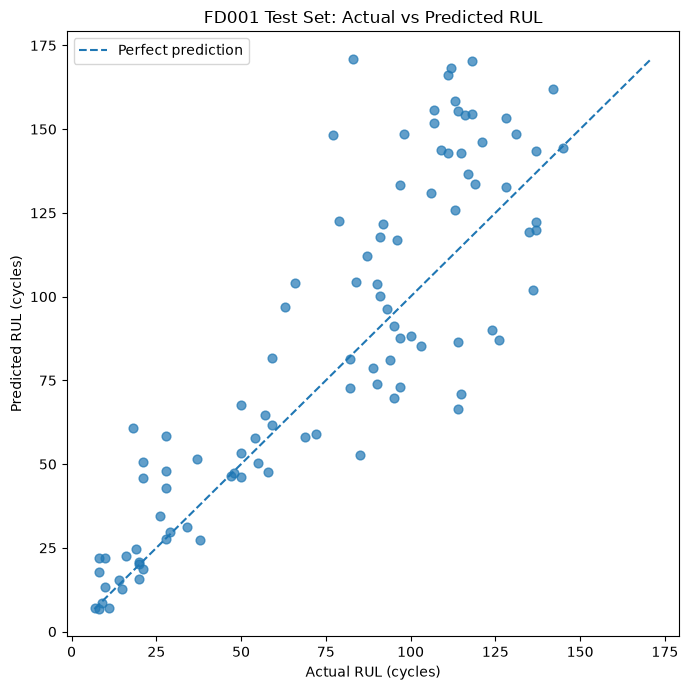

In [15]:
plt.figure(figsize=(7, 7))

plt.scatter(
    y_test,
    test_predictions,
    alpha=0.7,
    s=40
)

minimum_value = min(
    y_test.min(),
    test_predictions.min()
)

maximum_value = max(
    y_test.max(),
    test_predictions.max()
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Actual RUL (cycles)")
plt.ylabel("Predicted RUL (cycles)")
plt.title(
    "FD001 Test Set: Actual vs Predicted RUL"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "test_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

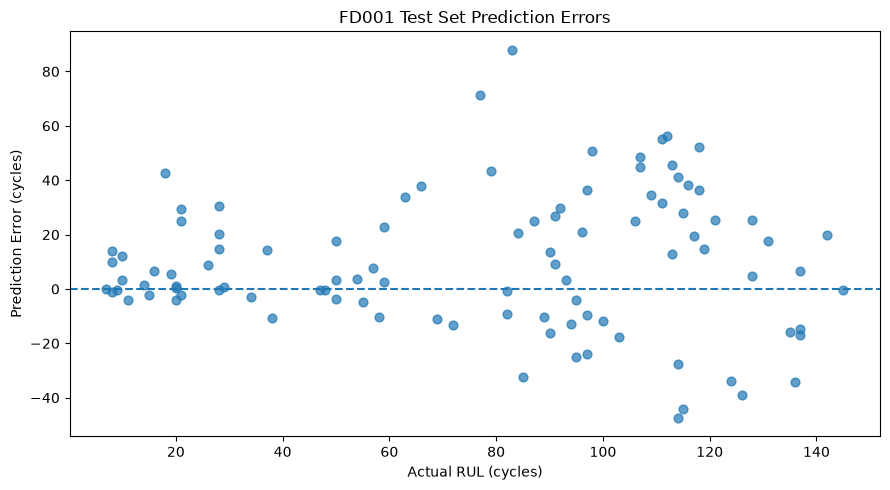

In [16]:
plt.figure(figsize=(9, 5))

plt.scatter(
    predictions["actual_RUL"],
    predictions["error"],
    alpha=0.7,
    s=40
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Actual RUL (cycles)")
plt.ylabel("Prediction Error (cycles)")
plt.title(
    "FD001 Test Set Prediction Errors"
)

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "test_residuals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
worst_predictions = (
    predictions
    .sort_values(
        "absolute_error",
        ascending=False
    )
    .head(10)
)

worst_predictions.round(2)

,engine_id,final_cycle,actual_RUL,predicted_RUL,error,absolute_error
14,15,76,83,170.99,87.99,87.99
66,67,71,77,148.36,71.36,71.36
0,1,31,112,168.40,56.40,56.40
21,22,39,111,166.02,55.02,55.02
84,85,34,118,170.28,52.28,52.28
1,2,49,98,148.70,50.70,50.70
77,78,72,107,155.70,48.70,48.70
44,45,152,114,66.51,-47.49,47.49
22,23,130,113,158.45,45.45,45.45
13,14,46,107,151.72,44.72,44.72


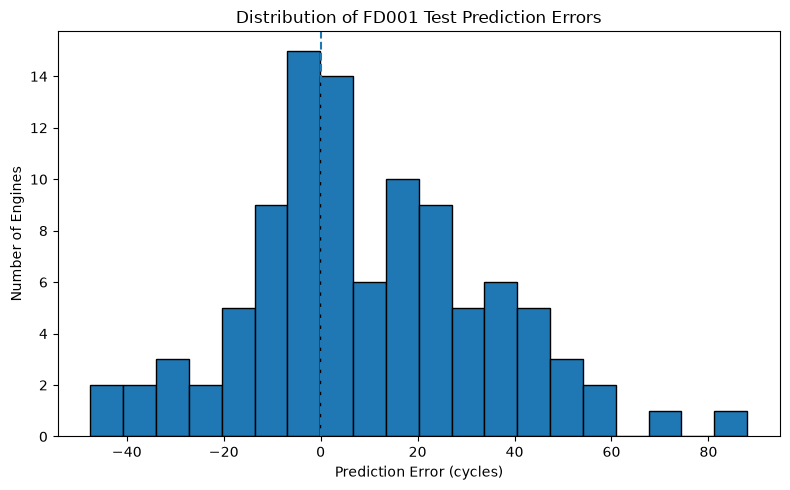

In [18]:
plt.figure(figsize=(8, 5))

plt.hist(
    predictions["error"],
    bins=20,
    edgecolor="black"
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel("Prediction Error (cycles)")
plt.ylabel("Number of Engines")
plt.title(
    "Distribution of FD001 Test Prediction Errors"
)

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "test_error_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [19]:
mean_error = predictions[
    "error"
].mean()

median_error = predictions[
    "error"
].median()

print(
    f"Mean prediction error: {mean_error:.2f} cycles"
)

print(
    f"Median prediction error: {median_error:.2f} cycles"
)

if mean_error > 0:
    print(
        "The model tends to overestimate RUL."
    )
elif mean_error < 0:
    print(
        "The model tends to underestimate RUL."
    )
else:
    print(
        "The model shows no average prediction bias."
    )

Mean prediction error: 9.75 cycles
Median prediction error: 6.04 cycles
The model tends to overestimate RUL.


In [20]:
test_metrics.to_csv(
    METRICS_PATH / "fd001_test_metrics.csv",
    index=False
)

predictions.to_csv(
    METRICS_PATH / "fd001_test_predictions.csv",
    index=False
)

print(
    "Metrics saved to:",
    METRICS_PATH / "fd001_test_metrics.csv"
)

print(
    "Predictions saved to:",
    METRICS_PATH / "fd001_test_predictions.csv"
)

Metrics saved to: /Users/aisha/mma3001-project/results/metrics/fd001_test_metrics.csv
Predictions saved to: /Users/aisha/mma3001-project/results/metrics/fd001_test_predictions.csv
